# Wu et al. 2020 — Acute Myeloid Leukemia (Microwell-seq)
## 01 · Preprocessing → malignant cell-state manifold

Load malignant cells across the four microwell Group leaves, threshold sparse samples, select over-dispersed genes, integrate samples with Harmony, embed, remove detached islands, and settle **Gate 1** (sample-mixed **and** continuous) on the regenerated embedding — not a scalar alone.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # Wu2020_Hematologic
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Hematologic
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Wu2020_Hematologic | category: Hematologic


**Load & concatenate the four microwell Group leaves.** Each Group ships its own gene panel; an outer join on genes keeps the union (absent genes fill 0), then select malignant cells.

In [3]:
# multi-leaf dataset: one matrix per Group; load each, keep malignant, concat (outer join on genes)
ads = []
for gd in sorted(glob.glob(os.path.join(pth_in, 'Group*'))):
    a = load_CCCA_adata(gd, verbose=False)
    a = a[a.obs['celltype'] == 'Malignant'].copy()
    a.obs['group'] = os.path.basename(gd)
    ads.append(a); print(os.path.basename(gd), a.shape, '| samples', a.obs['sample'].nunique())
adata = ad.concat(ads, join='outer', fill_value=0); adata.obs_names_make_unique()
print('malignant (all leaves):', adata.shape, '| samples', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Group1 (27294, 12507) | samples 6
Group2 (24200, 12020) | samples 9
Group3 (22408, 12988) | samples 9
Group4 (23128, 11759) | samples 14
malignant (all leaves): (97030, 13915) | samples 38
expression: X max 5.76 (log1p of normalize_total UMI counts)


**Sample threshold — derived, not inherited.** Look for a viability cliff where a per-sample count drops below the downstream kNN neighbourhood (NN=30); if the dominant gap is not a real spillover cliff, fall back to the ≥100 floor. Here the distribution is smooth down to 417, then two specks (98, 31) fall below the floor.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); NN = 30
ratios = vals[:-1] / vals[1:]; gap = int(np.argmax(ratios))
srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]; FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)   # a real spillover cliff?
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
thresh = int(np.sqrt(vals[gap]*vals[gap+1])) if dominant else FLOOR
print(('dominant cliff -> geometric-mean threshold = ' if dominant else 'no dominant cliff -> floor = ') + str(thresh))
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells; dropped', [s for s in n.index if s not in set(keep)])

sorted per-sample counts: {'P02': np.int64(8164), 'P12': np.int64(7340), 'P24': np.int64(6582), 'P03': np.int64(4826), 'P05': np.int64(4695), 'P08': np.int64(4528), 'P01': np.int64(4527), 'P19': np.int64(4201), 'P33': np.int64(4011), 'P28': np.int64(3914), 'P09': np.int64(3484), 'P06': np.int64(3098), 'P07': np.int64(3074), 'P20': np.int64(3031), 'P22': np.int64(2893), 'P21': np.int64(2822), 'P14': np.int64(2336), 'P31': np.int64(2315), 'P37': np.int64(2219), 'P32': np.int64(2202), 'P04': np.int64(1984), 'P25': np.int64(1657), 'P15': np.int64(1630), 'P27': np.int64(1471), 'P35': np.int64(1344), 'P16': np.int64(1234), 'P39': np.int64(1194), 'P36': np.int64(1142), 'P30': np.int64(834), 'P34': np.int64(751), 'P29': np.int64(679), 'P26': np.int64(635), 'P17': np.int64(588), 'P10': np.int64(543), 'P23': np.int64(536), 'P40': np.int64(417), 'P18': np.int64(98), 'P13': np.int64(31)}
argmax gap 417->98 (ratio 4.26); top/second = 1.35; dominant cliff = False
no dominant cliff -> floor = 100
kep

**Over-dispersed genes → PCA → Harmony integration.** Sweep the integration strength `theta` and read per-neighbourhood mixing with iLISI (effective #samples in a 30-NN neighbourhood); pick the strongest integration before mixing collapses.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
NP = 20
def ilisi(rep, labels, k=NN):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; out = np.empty(len(labels))
    for i in range(len(labels)):
        _, cnt = np.unique(codes[idx[i]], return_counts=True); p = cnt/cnt.sum()
        out[i] = 1.0/np.sum(p**2)
    return out.mean()
p_glob = adata.obs['sample'].value_counts(normalize=True).values
ceiling = 1.0/np.sum(p_glob**2)
pre = ilisi(adata.obsm['X_pca'][:,:NP], adata.obs['sample'].values)
sweep = {}
for th in [1, 2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = ilisi(adata.obsm['X_pca_harmony'][:,:NP], adata.obs['sample'].values)
print(f'#samples={adata.obs["sample"].nunique()} | iLISI ceiling (perfect mixing) = {ceiling:.2f}')
print('iLISI | pre-Harmony %.2f' % pre, '| sweep', {k: round(v,2) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(iLISI climbs to theta=10 then drops at 20; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NP, use_rep='X_pca_harmony', n_neighbors=NN, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 443 over-dispersed features (0:00:03) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 443
2026-08-04 19:45:33,611 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-04 19:45:41,756 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-04 19:45:42,825 - harmonypy - INFO - Iteration 1 of 30
2026-08-04 19:46:57,732 - harmonypy - INFO - Iteration 2 of 30
2026-08-04 19:48:12,674 - harmonypy - INFO - Converged after 2 iterations
2026-08-04 19:48:24,826 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-04 19:48:32,816 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-04 19:48:33,925 - harmonypy - INFO - Iteration 1 of

**Remove detached islands** — a UMAP radius graph at 6× the median nearest-neighbour distance; keep the single largest connected component (strictly conservative — only disconnected specks are stripped).

In [6]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands ->', int((lab==main).sum()), 'kept')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=NP, use_rep='X_pca_harmony', n_neighbors=NN, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

removed 20 cells in 17 detached islands -> 96881 kept


**Sub-region identity before Gate 1 (biology before geometry).** Cluster at low resolution and read the cycling fraction per lobe: a proliferation compartment would need scoping out. Microwell-seq here resolves a single low-cycling body.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('cycling fraction per lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
# single low-cycling body -> label uniformly; no proliferation compartment to scope out
adata.obs['compartment'] = 'Body'
adata.obs['compartment'] = adata.obs['compartment'].astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 96881}
overall cycling fraction: 0.001
cycling fraction per lobe: {'0': 0.001}
compartments: {'Body': 96881}


**Score the three developmental modules** (union control pool) and build a house linear orientation `X_umap_lin`: a rigid rotation aligning the manifold's principal axis to the x-axis, with the Gast/pSom-high (Crest-low) developmental-origin pole placed on the left. Every downstream panel uses this one orientation.

In [8]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = (S[:,0] + S[:,1]) - S[:,2]     # Gast+pSom-high / Crest-low = developmental origin
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[ np.cos(-theta_rot), -np.sin(-theta_rot)],
               [ np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg, Gast/pSom-high origin on left; stored as X_umap_lin')

Gast: 41/81 genes present
pSom: 47/98 genes present
Crest: 72/104 genes present
manifold aspect (max/min std): 1.36
house orientation: rigid rotation -5.9deg, Gast/pSom-high origin on left; stored as X_umap_lin


**Gate 1 readout.** iLISI on the integrated embedding versus its ceiling, one connected component after island removal — samples intermix per-neighbourhood on one continuous manifold.

In [9]:
n_samp = adata.obs['sample'].nunique()
il_post = sweep[theta]
print(f'iLISI post-Harmony(theta={theta}) = {il_post:.2f} of {ceiling:.2f} ceiling ({n_samp} samples)')
print(f'{n_samp} samples share one continuous manifold (one connected component; detached specks removed).')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO')

iLISI post-Harmony(theta=10) = 9.37 of 23.63 ceiling (36 samples)
36 samples share one continuous manifold (one connected component; detached specks removed).
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO


**Save `processed.h5ad`.**

In [10]:
protect = {'sample','group','compartment','lobe','celltype','cell_type','cell_subtype','cell_cycle_phase','patient'}
for cc in adata.obs.columns:
    if cc in protect:
        adata.obs[cc] = adata.obs[cc].astype(str).astype('category'); continue
    col = adata.obs[cc]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[cc] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (96881, 13907)


**Deliverable — `samples.pdf`** (single sample-colored manifold on the house orientation; intermixing across the strip is the Gate-1 batch-integration evidence).

saved samples.pdf | cells: 96881


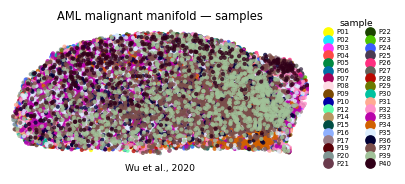

In [11]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=4.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('AML malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Wu et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])